# M03-6 | Quantizing Only Part of a Model, Composing Quantizers, Annotation Order

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m03_quantizer_api/06_partial_quantization.ipynb)

Real backends rarely quantize a whole model in one go:

- Some layers are sensitive to quantization and must stay in fp32 (mixed precision in M05).
- Some ops aren't supported by the hardware and can only fall back to CPU (M10).
- Different kinds of ops are handled by different Quantizers.

The three sections of this notebook:

- **A.** Partial quantization: use module names to decide which convs to quantize, and see what grows at the fp32/int8 boundary.
- **B.** `ComposableQuantizer`: one Quantizer per kind of op, and what it forbids.
- **C.** Annotation order: the big pattern (conv + relu) must be annotated first, or the small pattern (conv) grabs the node.


In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import the course's common/
    os.chdir(f"{repo}/en/m03_quantizer_api")

In [2]:
import copy

import torch
from torch.fx import Node

from common.data import calibration_batches
from common.graph_utils import observer_nodes, qdq_nodes
from common.models import example_inputs, get_model
from common.pt2e import (
    ANNOTATION_KEY,
    ComposableQuantizer,
    QuantizationAnnotation,
    Quantizer,
    annotate_input_qspec_map,
    annotate_output_qspec,
    convert_pt2e,
    export_module,
    get_module_name_filter,
    prepare_pt2e,
    quiet,
)
from common.qspecs import act_spec, weight_spec
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)
CONV2D = torch.ops.aten.conv2d.default
RELU = torch.ops.aten.relu.default
ADD = torch.ops.aten.add.Tensor

The rule-based Quantizers shared by all three sections. They all follow the style of M03-3: find ops by `node.target`, and leave nodes that are already annotated (`_annotated`) alone.


In [3]:
def find(gm, target):
    return [n for n in gm.graph.nodes if n.op == "call_function" and n.target == target]


def done(*nodes):
    """Whether any of these nodes has already been annotated."""
    return any((a := n.meta.get(ANNOTATION_KEY)) is not None and a._annotated for n in nodes)


def label_conv(conv, out):
    """The activation and weight input edges of conv, plus an output annotation (attached to out: the conv itself, or the relu after it)."""
    annotate_input_qspec_map(conv, conv.args[0], act_spec())
    annotate_input_qspec_map(conv, conv.args[1], weight_spec())
    annotate_output_qspec(out, act_spec())
    for node in (conv, out):
        node.meta[ANNOTATION_KEY]._annotated = True


class RuleQuantizer(Quantizer):
    def validate(self, model):
        pass


class ConvQuantizer(RuleQuantizer):
    """Quantize conv2d. include is a node -> bool function deciding which convs to quantize (all by default)."""

    def __init__(self, include=None):
        self.include = include

    def annotate(self, model):
        for conv in find(model, CONV2D):
            if not done(conv) and (self.include is None or self.include(conv)):
                label_conv(conv, conv)
        return model


class ConvReluQuantizer(RuleQuantizer):
    """Quantize conv + relu: the output annotation goes on relu, and nothing is quantized between conv and relu."""

    def annotate(self, model):
        for relu in find(model, RELU):
            conv = relu.args[0]
            # if the conv output has other users, conv + relu is not a self-contained pattern
            if conv.op == "call_function" and conv.target == CONV2D and len(conv.users) == 1 and not done(conv, relu):
                label_conv(conv, relu)
        return model


class AddQuantizer(RuleQuantizer):
    """Quantize the activation inputs and output of add (excluding scalars and model constants)."""

    def annotate(self, model):
        for add in find(model, ADD):
            inputs = [a for a in add.args[:2] if isinstance(a, Node) and a.op != "get_attr"]
            if inputs and not done(add):
                for a in inputs:
                    annotate_input_qspec_map(add, a, act_spec())
                annotate_output_qspec(add, act_spec())
                add.meta[ANNOTATION_KEY]._annotated = True
        return model

## A. Partial Quantization: Use Module Names to Decide Which Convs to Quantize

The `tiny` model has three segments: `stem`, `block`, `head_conv`. torchao's `get_module_name_filter("stem")` returns a `node -> bool` function:
whether this node comes from the submodule named `stem` (it looks at `node.meta["nn_module_stack"]`). Pass it to `ConvQuantizer` as `include`, and convs not on the list get no annotation.


In [4]:
def calibrate(prepared):
    with torch.no_grad():
        for batch in calibration_batches(n=64, batch_size=16):
            prepared(*batch)


model = get_model("tiny").eval()
gm_tiny = export_module(model, example_inputs(8))
configs = [("all convs", None)] + [(f"only {name}", get_module_name_filter(name)) for name in ("stem", "block", "head_conv")]
rows, converted = [], {}
for title, include in configs:
    prepared = prepare_pt2e(copy.deepcopy(gm_tiny), ConvQuantizer(include))
    n_obs = len(observer_nodes(prepared))
    calibrate(prepared)
    converted[title] = convert_pt2e(prepared)
    rows.append([title, n_obs, len(qdq_nodes(converted[title]))])
table(rows, ["setting", "# observers", "# q/dq"])

setting,# observers,# q/dq
all convs,12,20
only stem,3,5
only block,6,10
only head_conv,3,5


A conv not on the list has no annotation; `prepare_pt2e` inserts no observer for it, and it and the ops after it stay in fp32.
Lay out the ops of "only stem" after convert in one line (q = quantize, dq = dequantize) and look at the boundary between int8 and fp32:


In [5]:
def sequence(gm):
    def short(n):
        t = str(n.target)
        return "dq" if "dequantize" in t else "q" if "quantize" in t else n.name.rstrip("_0123456789")
    return " ".join(short(n) for n in gm.graph.nodes if n.op == "call_function")


chain = sequence(converted["only stem"])
print(chain)

dq q dq conv2d q dq relu max_pool2d conv2d relu conv2d add relu max_pool2d conv2d relu adaptive_avg_pool2d flatten linear


In [6]:
assert chain.startswith("dq q dq conv2d q dq relu")
assert "q" not in chain.split("relu", 1)[1].split()  # no more q/dq after stem

- The lone `dq` at the very front is stem's weight: it has already been pre-quantized into an int8 constant, leaving only a dequantize at run time.
- Then `q dq conv2d q dq`: one q/dq pair each on the input and output of stem's conv. Everything after that is fp32.

q/dq appear only around the quantized conv; this is the boundary between fp32 and int8. The more boundaries, the larger the q/dq overhead, so backends prefer to quantize long contiguous stretches.
Backends wrap this in config APIs such as `set_module_name`, which M03-7 will show.

## B. ComposableQuantizer: One Quantizer per Kind of Op

`ComposableQuantizer([q1, q2, ...])` calls each Quantizer's `annotate` in order. Each Quantizer focuses only on its own kind of op, and together they cover the whole model.
On the residual model, first use only `ConvQuantizer`, then add `AddQuantizer`:


In [7]:
gm_res = export_module(get_model("residual").eval(), example_inputs(4))
only_conv = prepare_pt2e(copy.deepcopy(gm_res), ConvQuantizer())
composed = prepare_pt2e(copy.deepcopy(gm_res), ComposableQuantizer([ConvQuantizer(), AddQuantizer()]))
print("ConvQuantizer only: observers", len(observer_nodes(only_conv)))
print("ConvQuantizer + AddQuantizer: observers", len(observer_nodes(composed)))
assert len(observer_nodes(composed)) == len(observer_nodes(only_conv)) + 1

ConvQuantizer only: observers 6
ConvQuantizer + AddQuantizer: observers 7


Which one is the extra? Draw only the area around add: on the left only `ConvQuantizer`, on the right `AddQuantizer` added; the green boxes are the newly grown observers:


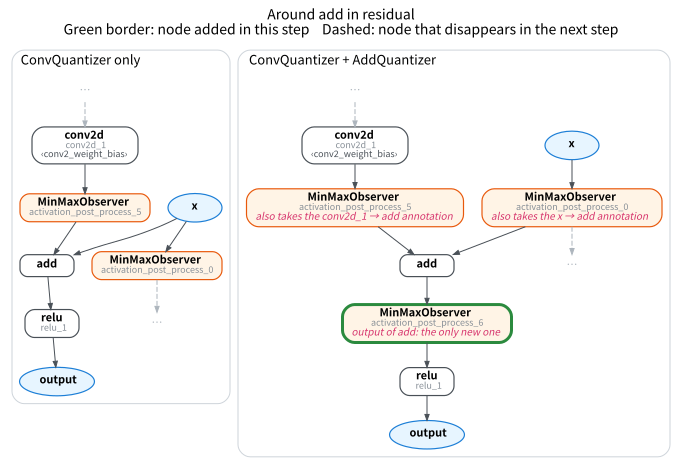

In [8]:
add = next(n for n in composed.graph.nodes if n.target == ADD)
from_conv, from_x = add.args[0], add.args[1]  # the two inputs of add, now both observers
draw_stages([(only_conv, "ConvQuantizer only"), (composed, "ConvQuantizer + AddQuantizer")], focus="add", hops=2,
            notes=[{}, {from_conv.name: "also takes the conv2d_1 → add annotation", from_x.name: "also takes the x → add annotation",
                        next(iter(add.users)).name: "output of add: the only new one"}],
            title="Around add in residual")

In [9]:
conv = next(n for n in composed.graph.nodes if n.target == CONV2D)
assert from_x is conv.args[0]  # the x that add takes is the same observer the first conv takes
assert from_conv.args[0].name == "conv2d_1"  # the conv output that add takes is the existing output observer of conv2d_1

Only one is added, the output of add. The two input edges of add were also annotated, but they didn't each grow an observer; they merged into the existing observers:

- **`conv2d_1 → add`**: `ConvQuantizer` already annotated the output of `conv2d_1`; the two annotations have identical attributes and share one observer.
- **`x → add`**: in the left graph add takes the original `x` directly (not quantized); in the right graph it takes `x`'s existing observer, the one the first conv uses. The two edges' annotations have identical attributes and merge into one.

This is the implicit sharing of M03-4: annotations with identical attributes on the same tensor quantize only once.

What `ComposableQuantizer` forbids: after each Quantizer's `annotate`, it checks whether annotations already attached earlier have been replaced or deleted, and raises an error if so.
The `MeddlingQuantizer` below replaces the conv's annotation entirely with an empty one, and is placed after `ConvQuantizer`:


In [10]:
class MeddlingQuantizer(RuleQuantizer):
    def annotate(self, model):
        for conv in find(model, CONV2D):
            conv.meta[ANNOTATION_KEY] = QuantizationAnnotation()
        return model


try:
    prepare_pt2e(copy.deepcopy(gm_res), ComposableQuantizer([ConvQuantizer(), MeddlingQuantizer()]))
    raised = None
except RuntimeError as e:
    raised = e
print("RuntimeError:", raised)
assert raised is not None

RuntimeError: Quantizer MeddlingQuantizer has changed annotations on node conv2d


So later Quantizers can only fill in nodes that have no annotation yet, and can't change anyone else's. Checking `_annotated` at the start of every `annotate` (`done()` here) is to honor this convention.

## C. Annotation Order: Big Pattern First

`ConvReluQuantizer` (big pattern) and `ConvQuantizer` (small pattern) both want to annotate the same conv. Whoever goes first takes it.
For the same conv → relu, prepare once with each order:


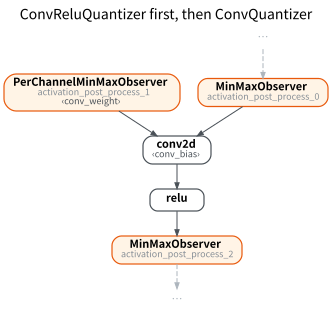

In [11]:
gm_cr = export_module(get_model("conv_relu").eval(), example_inputs(4))
big_first = prepare_pt2e(copy.deepcopy(gm_cr), ComposableQuantizer([ConvReluQuantizer(), ConvQuantizer()]))
draw(big_first, focus=["conv2d", "relu"], title="ConvReluQuantizer first, then ConvQuantizer")

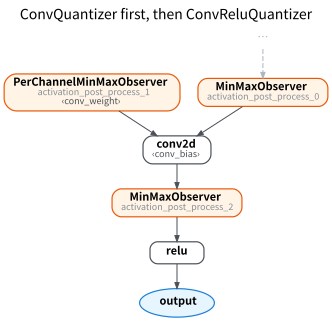

In [12]:
small_first = prepare_pt2e(copy.deepcopy(gm_cr), ComposableQuantizer([ConvQuantizer(), ConvReluQuantizer()]))
draw(small_first, focus=["conv2d", "relu"], title="ConvQuantizer first, then ConvReluQuantizer")

In [13]:
def observer_before_relu(gm):
    relu = next(n for n in gm.graph.nodes if n.target == RELU)
    return relu.args[0].op == "call_module"


print("Big pattern first: observer between conv and relu?", observer_before_relu(big_first))
print("Small pattern first: observer between conv and relu?", observer_before_relu(small_first))
assert not observer_before_relu(big_first) and observer_before_relu(small_first)

Big pattern first: observer between conv and relu? False
Small pattern first: observer between conv and relu? True


- **Big pattern first**: `ConvReluQuantizer` annotates the conv and relu and sets `_annotated`; `ConvQuantizer` sees that the conv is already annotated and skips it. The quantization point is after relu, with no observer between conv and relu.
- **Small pattern first**: `ConvQuantizer` takes the conv first (annotating its output too), and `ConvReluQuantizer` finds the conv already annotated and gives up. There is an extra quantization point between conv and relu, so the backend can't fuse the two into one kernel.

Both orders are legal and both run; only the results differ. The order is the Quantizer author's responsibility: the `STATIC_OPS` of the torchao test-version XNNPACKQuantizer
is `linear_relu`, `linear`, `conv_relu`, `conv`... in that order, again with the bigger ones first.

## Summary

- Partial quantization: ops without annotations stay in fp32, and q/dq grow at the boundary. Use `get_module_name_filter` to pick nodes by module name.
- `ComposableQuantizer` calls several Quantizers in order; later ones can only fill in, not change annotations attached earlier.
- Annotation order decides the result: big patterns must come before small patterns.
